# Bank Marketing — Final Model Evaluation

## Objective

This notebook performs the final evaluation of the selected
HistGradientBoosting model on the held-out test set.

The model configuration and decision threshold were selected using
cross-validation on the training data. No further model or threshold
changes will be made based on the test results.

The same test split was previously used to establish the Logistic
Regression baseline, but it was not used to select or tune the final
candidate model.

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path

import joblib
import numpy as np
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [2]:
df = pd.read_csv(
    "../data/raw/bank-full.csv",
    sep=";",
)

X = df.drop(columns=["y", "duration"]).copy()

y = df["y"].map({
    "no": 0,
    "yes": 1,
})

In [3]:
X["previously_contacted"] = (
    X["pdays"] != -1
).astype("int8")

X["pdays"] = X["pdays"].replace(-1, 0)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

In [5]:
categorical_features = X_train.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numeric_features = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous",
]

binary_features = [
    "previously_contacted",
]

In [6]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median"),
        ),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent"),
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False,
            ),
        ),
    ]
)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features,
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features,
        ),
        (
            "binary",
            "passthrough",
            binary_features,
        ),
    ]
)

In [8]:
SELECTED_THRESHOLD = 0.645058

In [9]:
final_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor,
        ),
        (
            "classifier",
            HistGradientBoostingClassifier(
                learning_rate=0.05,
                max_iter=300,
                max_leaf_nodes=63,
                min_samples_leaf=10,
                l2_regularization=10.0,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

In [10]:
final_pipeline.fit(
    X_train,
    y_train,
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['age','job','marital',...,'previous','poutcome','previously_contacted']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [11]:
test_probabilities = final_pipeline.predict_proba(
    X_test
)[:, 1]

In [12]:
default_threshold_predictions = (
    test_probabilities >= 0.5
).astype(int)

selected_threshold_predictions = (
    test_probabilities >= SELECTED_THRESHOLD
).astype(int)

In [13]:
def calculate_test_metrics(
    y_true,
    predictions,
    probabilities,
):
    return pd.Series({
        "accuracy": accuracy_score(
            y_true,
            predictions,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            predictions,
        ),
        "precision": precision_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "recall": recall_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "f1_score": f1_score(
            y_true,
            predictions,
            zero_division=0,
        ),
        "roc_auc": roc_auc_score(
            y_true,
            probabilities,
        ),
        "average_precision": average_precision_score(
            y_true,
            probabilities,
        ),
        "predicted_positives": predictions.sum(),
    })

In [14]:
final_results = pd.concat(
    [
        calculate_test_metrics(
            y_test,
            default_threshold_predictions,
            test_probabilities,
        ).rename("threshold_0.5"),
        calculate_test_metrics(
            y_test,
            selected_threshold_predictions,
            test_probabilities,
        ).rename("threshold_0.645"),
    ],
    axis=1,
)

final_results

,threshold_0.5,threshold_0.645
accuracy,0.826274,0.875041
balanced_accuracy,0.740919,0.726716
precision,0.360976,0.470000
recall,0.629490,0.533081
f1_score,0.458836,0.499557
roc_auc,0.806023,0.806023
average_precision,0.467404,0.467404
predicted_positives,1845.000000,1200.000000


In [15]:
print(
    classification_report(
        y_test,
        selected_threshold_predictions,
        target_names=["no", "yes"],
        zero_division=0,
    )
)

              precision    recall  f1-score   support

          no       0.94      0.92      0.93      7985
         yes       0.47      0.53      0.50      1058

    accuracy                           0.88      9043
   macro avg       0.70      0.73      0.71      9043
weighted avg       0.88      0.88      0.88      9043



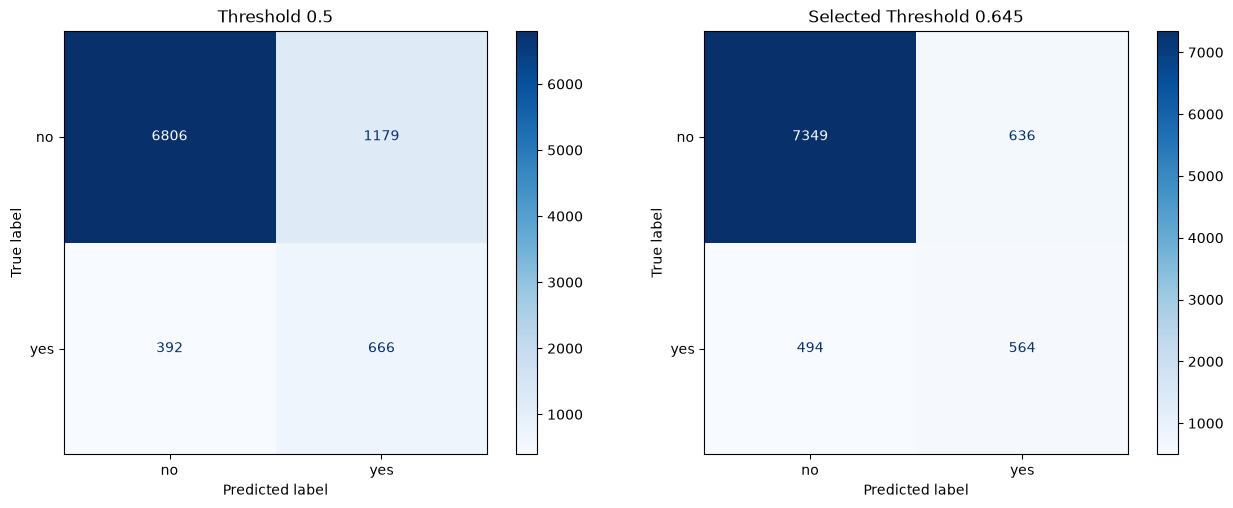

In [16]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    default_threshold_predictions,
    display_labels=["no", "yes"],
    cmap="Blues",
    values_format="d",
    ax=axes[0],
)

axes[0].set_title("Threshold 0.5")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    selected_threshold_predictions,
    display_labels=["no", "yes"],
    cmap="Blues",
    values_format="d",
    ax=axes[1],
)

axes[1].set_title("Selected Threshold 0.645")

plt.tight_layout()
plt.show()

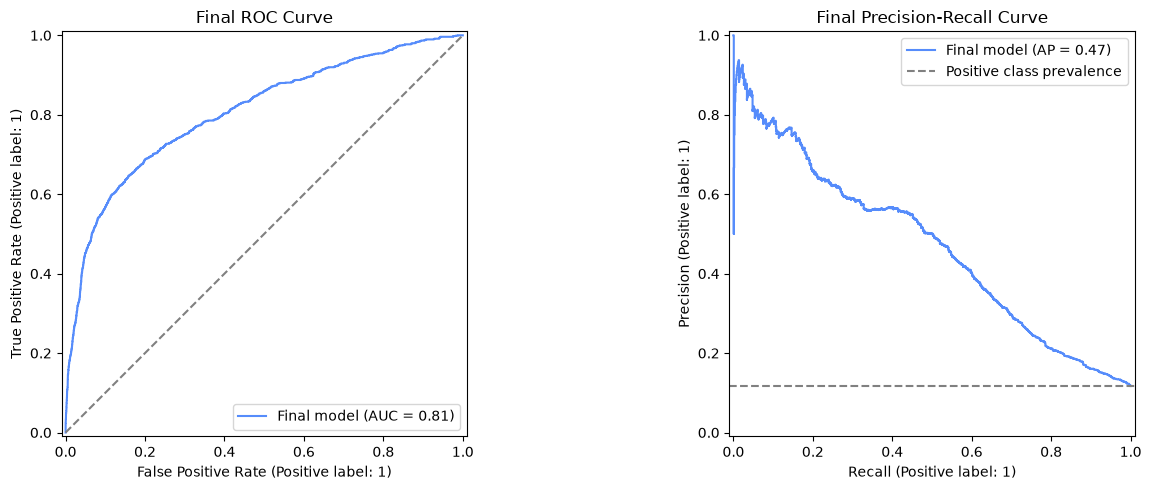

In [17]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Final model",
    ax=axes[0],
)

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
)

axes[0].set_title("Final ROC Curve")

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Final model",
    ax=axes[1],
)

axes[1].axhline(
    y=y_test.mean(),
    linestyle="--",
    color="gray",
    label="Positive class prevalence",
)

axes[1].set_title("Final Precision-Recall Curve")
axes[1].legend()

plt.tight_layout()
plt.show()

## Final Evaluation Findings

- The final model was evaluated on 9,043 held-out observations, including 1,058 subscribers.
- The model achieves a test ROC-AUC of 0.806 and an average precision of 0.467. Both results are slightly higher than their corresponding cross-validation estimates, indicating consistent generalization.
- At the default threshold of 0.5, the model obtains 36.10% precision, 62.95% recall, and an F1-score of 0.459.
- The selected threshold of 0.645 increases precision to 47.00% and F1-score to 0.500, while recall decreases to 53.31%.
- At the selected threshold, the model correctly identifies 564 of the 1,058 subscribers and misses 494.
- The model produces 636 false-positive predictions and correctly rejects 7,349 non-subscribers.
- Increasing the threshold from 0.5 to 0.645 removes 543 false positives at the cost of 102 additional false negatives.
- The selected threshold increases accuracy from 82.63% to 87.50%, although balanced accuracy decreases slightly from 74.09% to 72.67%.
- Compared with the Logistic Regression baseline, the final model provides substantially higher positive-class recall, F1-score, ROC-AUC, and average precision.
- The final threshold represents a balanced F1-oriented operating point. A real marketing campaign could select a different threshold according to contact costs and the estimated value of identifying additional subscribers.
- The `duration` feature was excluded, so the model does not depend on information available only after completion of the customer call.

In [19]:
model_path = Path(
    "../models/final_model.joblib"
)

model_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

In [20]:
model_artifact = {
    "pipeline": final_pipeline,
    "decision_threshold": SELECTED_THRESHOLD,
    "feature_columns": X.columns.tolist(),
    "target_mapping": {
        "no": 0,
        "yes": 1,
    },
    "excluded_features": [
        "duration",
    ],
    "sklearn_version": sklearn.__version__,
}

In [21]:
joblib.dump(
    model_artifact,
    model_path,
)

model_path

PosixPath('../models/final_model.joblib')

In [22]:
loaded_artifact = joblib.load(
    model_path
)

reloaded_probabilities = (
    loaded_artifact["pipeline"]
    .predict_proba(X_test)[:, 1]
)

assert np.allclose(
    test_probabilities,
    reloaded_probabilities,
)

assert (
    loaded_artifact["decision_threshold"]
    == SELECTED_THRESHOLD
)

print("Model artifact saved and verified.")

Model artifact saved and verified.
